### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2. Food Exports Price Dataset

In [8]:
temp_food_exports = get_dataset('\\Datasets\\food_exports_percentage.csv')
temp_food_exports.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,Food exports (% of merchandise exports),TX.VAL.FOOD.ZS.UN,NaN,NaN,NaN,NaN,NaN,NaN,...,77.686012,74.968215,74.673023,68.293588,59.034232,50.346782,44.106834,41.646371,43.626885,50.246868
1,Africa Eastern and Southern,AFE,Food exports (% of merchandise exports),TX.VAL.FOOD.ZS.UN,NaN,NaN,NaN,NaN,NaN,NaN,...,11.240680,12.045652,14.049433,13.130595,14.393644,14.730160,14.790954,14.181939,13.177237,17.340667
2,Afghanistan,AFG,Food exports (% of merchandise exports),TX.VAL.FOOD.ZS.UN,NaN,NaN,31.947026,26.51912,32.603264,41.067461,...,39.145175,17.437223,13.638505,14.495624,48.456109,56.918875,71.159014,65.896563,63.852107,NaN
3,Africa Western and Central,AFW,Food exports (% of merchandise exports),TX.VAL.FOOD.ZS.UN,NaN,NaN,59.577918,57.48915,56.270284,52.277882,...,12.998649,13.079052,12.505634,13.009586,15.949690,16.549540,15.028588,15.160601,13.198671,NaN
4,Angola,AGO,Food exports (% of merchandise exports),TX.VAL.FOOD.ZS.UN,NaN,NaN,65.494825,NaN,NaN,NaN,...,0.038704,0.063120,0.073454,0.085171,0.314687,0.605232,0.422553,0.339628,0.322497,NaN


In [9]:
temp_food_exports = temp_food_exports[temp_food_exports['Country Code'] == 'MMR']
temp_food_exports

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,Food exports (% of merchandise exports),TX.VAL.FOOD.ZS.UN,NaN,NaN,77.098693,78.210063,77.099854,74.9634,...,28.405115,33.516046,28.561681,26.903281,31.901653,37.32331,32.217862,26.045386,24.221785,28.89938


In [10]:
date = temp_food_exports.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
food_exports_percent = temp_food_exports.copy()
food_exports_percent = food_exports_percent[date]
food_exports_percent = food_exports_percent.values
food_exports_percent

array([[        nan,         nan, 77.09869346, 78.21006265, 77.0998537 ,
        74.96340026, 72.01613521, 68.85670763, 58.25509744, 61.97737248,
        65.81096213, 64.33497078, 53.63095321, 32.73648   , 52.65739626,
        58.86731415, 64.20011525,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan, 53.39322883,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
        17.31104657, 28.40511458, 33.51604583, 28.56168139, 26.9032809 ,
        31.90165334, 37.32331004, 32.21786189, 26.04538603, 24.22178532,
        28.89938035]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
food_exports_percent = food_exports_percent[0]
food_exports_percent.shape

(61,)

In [15]:
food_exports = pd.DataFrame()
food_exports['food_exports_percent'] = food_exports_percent
food_exports

,food_exports_percent
0,NaN
1,NaN
2,77.098693
3,78.210063
4,77.099854
...,...
56,37.323310
57,32.217862
58,26.045386
59,24.221785


##### Filling data with linear interpolation

In [16]:
food_exports = food_exports.interpolate(method='linear')
food_exports

,food_exports_percent
0,NaN
1,NaN
2,77.098693
3,78.210063
4,77.099854
...,...
56,37.323310
57,32.217862
58,26.045386
59,24.221785


In [17]:
food_exports['date']=date
food_exports = food_exports.set_index('date')
food_exports.columns=['food_exports_percent']
food_exports.head()

,food_exports_percent
date,
1960-01-01,NaN
1961-01-01,NaN
1962-01-01,77.098693
1963-01-01,78.210063
1964-01-01,77.099854


In [18]:
food_exports = food_exports.dropna()
food_exports.head()

,food_exports_percent
date,
1962-01-01,77.098693
1963-01-01,78.210063
1964-01-01,77.099854
1965-01-01,74.963400
1966-01-01,72.016135


### Merge Food Export and Food Price

In [19]:
food_price_exports = food_price.join(food_exports, how='inner')
food_price_exports

,food_price,food_exports_percent
date,,
2008-01-01,0.563348,21.320178
2009-01-01,0.452433,19.315612
2010-01-01,0.505708,17.311047
2011-01-01,0.546463,28.405115
2012-01-01,0.467904,33.516046
2013-01-01,0.513739,28.561681
2014-01-01,0.918071,26.903281
2015-01-01,1.059368,31.901653
2016-01-01,1.182692,37.323310


### Compute price change using pct_change()

Even if the two series are totally unrelated, you could still get a very high correlation. 
We should use priceage of data instead of original data.

In [20]:
returns= food_price_exports.pct_change()
returns

,food_price,food_exports_percent
date,,
2008-01-01,NaN,NaN
2009-01-01,-0.196887,-0.094022
2010-01-01,0.117753,-0.103780
2011-01-01,0.080591,0.640866
2012-01-01,-0.143759,0.179930
2013-01-01,0.097959,-0.147821
2014-01-01,0.787035,-0.058064
2015-01-01,0.153907,0.185790
2016-01-01,0.116412,0.169949


In [21]:
correlation=returns['food_price'].corr(returns['food_exports_percent'])
correlation

-0.1392214114536437

### Make scatter plot

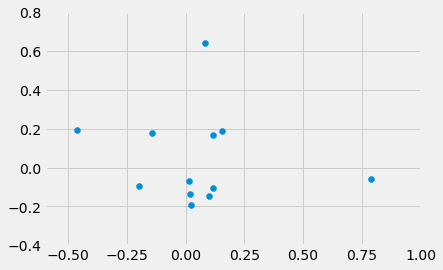

In [22]:
plt.scatter(returns['food_price'],returns['food_exports_percent'])
plt.show()

### Normalization

In [23]:
date = food_price_exports.index

In [24]:
scaler = MinMaxScaler()

In [25]:
food_price_exports = scaler.fit_transform(food_price_exports)
food_price_exports = pd.DataFrame(food_price_exports)
food_price_exports['date'] = date
food_price_exports.set_index('date', inplace=True)
food_price_exports.columns = ['food_price', 'food_exports_percent']
food_price_exports.head()

,food_price,food_exports_percent
date,,
2008-01-01,0.138512,0.200334
2009-01-01,0.000000,0.100167
2010-01-01,0.066530,0.000000
2011-01-01,0.117426,0.554363
2012-01-01,0.019321,0.809753


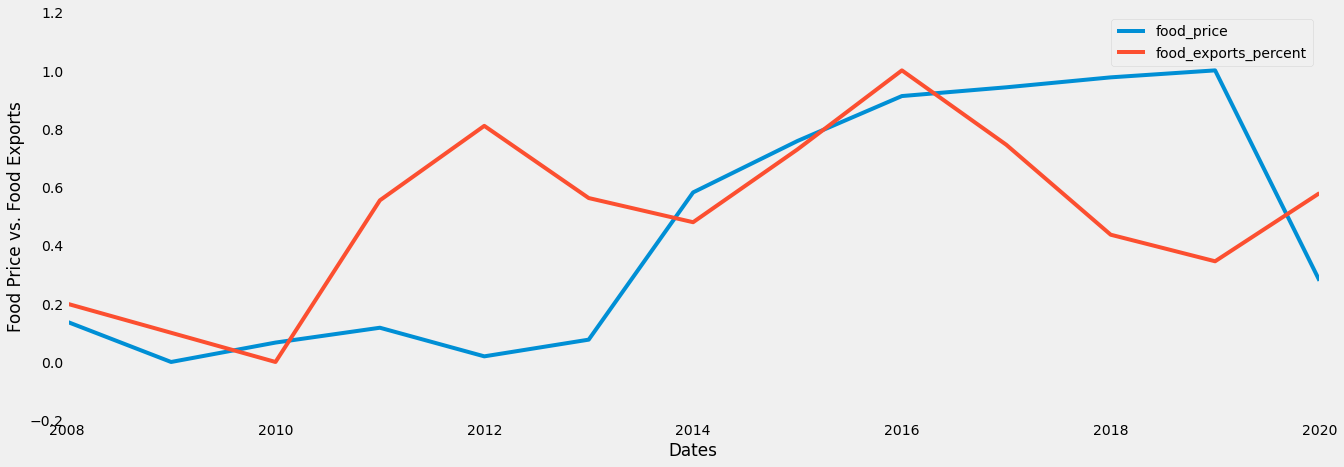

In [26]:
line_ax = food_price_exports.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Food Exports')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is some positive relation between Food Price and Food Export Percentage</span>